In [1]:
import torch
import torch.nn as nn
import timm
from transformers import CLIPVisionModel
from transformers import (
    CLIPVisionModel, CLIPProcessor
)

# Even better approach - use timm for all three for maximum consistency:
class ViTWithCustomHead(nn.Module):    
    def __init__(self, model_name, num_classes, pretrained_type='imagenet'):
        super(ViTWithCustomHead, self).__init__()
        
        # Map pretrained types to timm model names (all patch16, 224x224)
        model_mapping = {
            'ImageNet-21k': 'vit_base_patch16_224.augreg_in21k_ft_in1k',
            'CLIP': 'vit_base_patch16_clip_224.openai',  # CLIP weights via timm
            'DINOv2': 'vit_base_patch16_224.dino'        # DINO weights via timm
        }
        
        if pretrained_type not in model_mapping:
            raise ValueError(f"Unknown pretrained_type: {pretrained_type}")
            
        # Create model without head (num_classes=0)
        self.vit = timm.create_model(model_mapping[pretrained_type], pretrained=True, num_classes=0)
        # Add custom head
        self.vit.head = nn.Linear(self.vit.num_features, num_classes)
        
        self.pretrained_type = pretrained_type
    
    def forward(self, x):
        return self.vit(x)


# num_classes = 10

# # Create models with same architecture but different pretrained weights
# model_imagenet = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'imagenet')
# model_clip = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'clip')
# model_dinov2 = ViTWithCustomHead('vit_base_patch16_224', num_classes, 'dinov2')

# # Test with dummy input - all models expect the same input format
# x = torch.randn(1, 3, 224, 224)

# print("ImageNet ViT output shape:", model_imagenet(x).shape)
# print("CLIP ViT output shape:", model_clip(x).shape)
# print("DINOv2 ViT output shape:", model_dinov2(x).shape)

# # Verify they have the same architecture
# print(f"\nImageNet params: {sum(p.numel() for p in model_imagenet.parameters()):,}")
# print(f"CLIP params: {sum(p.numel() for p in model_clip.parameters()):,}")
# print(f"DINOv2 params: {sum(p.numel() for p in model_dinov2.parameters()):,}")

2025-09-28 19:05:55.023656: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1759086355.196517      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1759086355.245938      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [ ]:
# def model_size_mb(model):
#     total_params = sum(p.numel() for p in model.parameters())
#     size_mb = total_params * 4 / (1024 ** 2)  # float32 = 4 bytes
#     return total_params, size_mb

# params, size = model_size_mb(model_imagenet)
# print(f"{name} -> Params: {params:,} | Size: {size:.2f} MB")

In [3]:
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
import pandas as pd
import numpy as np
from PIL import Image
import os

from sklearn.metrics import f1_score, roc_auc_score, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt

from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

def load_and_split_data(train_csv_path, test_csv_path, val_size=0.2, random_state=42):
    train_df = pd.read_csv(train_csv_path)
    test_df = pd.read_csv(test_csv_path)

    # Keep only required columns and standardize names
    train_df = train_df[['filenames', 'labels']].copy()
    train_df.columns = ['filenames', 'labels']
    
    print(f"Dataset shape: {train_df.shape}")
    print(f"Classes: {train_df['labels'].unique()}")
    print(f"Class distribution:\n{train_df['labels'].value_counts()}")
    
    train_df, val_df = train_test_split(
        train_df, test_size=val_size, 
        stratify=train_df['labels'], 
        random_state=random_state
    )
    
    print(f"\nData split:")
    print(f"Train set: {len(train_df)} samples")
    print(f"Validation set: {len(val_df)} samples") 
    print(f"Test set: {len(test_df)} samples")
    
    return train_df, val_df, test_df

class OrthonetDataset(Dataset):
    """Custom dataset class for Orthonet X-ray images"""

    def __init__(self, df, root_dir, transform=None, processor=None):
        # Extract filenames and labels
        self.filenames = df['filenames'].tolist()
        self.labels = df['labels'].tolist()

        # Encode labels
        self.label_encoder = LabelEncoder()
        self.labels = self.label_encoder.fit_transform(self.labels)

        self.num_classes = len(self.label_encoder.classes_)

        self.root_dir = root_dir
        self.transform = transform
        self.processor = processor

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.item()

        img_path = os.path.join(self.root_dir, self.filenames[idx])
        image = Image.open(img_path).convert('RGB')
        label = self.labels[idx]

        if self.processor is not None:
            image = self.processor(images=image, return_tensors="pt")['pixel_values'].squeeze(0)
        elif self.transform:
            image = self.transform(image)

        return image, label

In [4]:
def create_transforms():
    """
    These are applicable to Imagenet-21K and DinoV2. Clip uses a different set of normalisation coefficients
    which are applied using the CLIPProcessor.
    """
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                           std=[0.229, 0.224, 0.225])
    ])

    val_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], 
                           std=[0.229, 0.224, 0.225])
    ])
    
    return train_transform, val_transform

def create_clip_processor():
    return CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

In [5]:
def evaluate_model(model, dataloader, device):
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            
            probs = F.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)
            
            all_preds.append(preds.cpu())
            all_labels.append(labels.cpu())
            all_probs.append(probs.cpu())

    # Concatenate all batches
    all_preds = torch.cat(all_preds).numpy()
    all_labels = torch.cat(all_labels).numpy()
    all_probs = torch.cat(all_probs).numpy()
    
    # Accuracy
    acc = 100.0 * (all_preds == all_labels).mean()
    
    # Macro F1-score
    f1 = f1_score(all_labels, all_preds, average='macro')
    
    # Macro AUC
    try:
        auc = roc_auc_score(all_labels, all_probs, multi_class='ovo', average='macro')
    except ValueError:
        auc = None  # Some classes may be missing in predictions
    
    return acc, f1, auc

In [7]:
def train_model(model, train_loader, val_loader, num_epochs=10, lr=1e-4, device='cuda'):
    """Train the model with cosine annealing scheduler"""
    
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs, eta_min=1e-6)
    
    train_losses = []
    train_accuracies = []
    val_accuracies = []
    best_val_acc = 0.0
    best_model_state = None
    
    for epoch in range(num_epochs):
        # Training phase
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0
        
        pbar = tqdm(train_loader, desc=f'Epoch {epoch+1}/{num_epochs}')
        for batch_idx, (data, targets) in enumerate(pbar):
            data, targets = data.to(device), targets.to(device)
            
            optimizer.zero_grad()
            outputs = model(data)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += targets.size(0)
            train_correct += (predicted == targets).sum().item()
            
            pbar.set_postfix({
                'Loss': f'{loss.item():.4f}',
                'Acc': f'{100.*train_correct/train_total:.2f}%'
            })
        
        train_acc = 100. * train_correct / train_total
        avg_train_loss = train_loss / len(train_loader)
        
        # Validation phase
        val_acc, _, _ = evaluate_model(model, val_loader, device)
        
        train_losses.append(avg_train_loss)
        train_accuracies.append(train_acc)
        val_accuracies.append(val_acc)
        
        print(f'Epoch [{epoch+1}/{num_epochs}]')
        print(f'Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc:.2f}%')
        print(f'Val Acc: {val_acc:.2f}%')
        print('-' * 50)
        
        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_state = model.state_dict().copy()
        
        # Step the cosine annealing scheduler
        scheduler.step()
    
    # Load best model
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    return model, train_losses, train_accuracies, val_accuracies

In [8]:
import matplotlib.pyplot as plt

def plot_training_curves(train_losses, train_accuracies, val_accuracies, model_name):
    epochs = range(1, len(train_losses) + 1)

    fig, axs = plt.subplots(1, 2, figsize=(12, 5))

    # ---- Plot Training Loss ----
    axs[0].plot(epochs, train_losses, marker="o", color="tab:red", label="Training Loss")
    axs[0].set_title(f"{model_name} - Training Loss")
    axs[0].set_xlabel("Epoch")
    axs[0].set_ylabel("Loss")
    axs[0].grid(True)
    axs[0].legend()

    # ---- Plot Accuracy ----
    axs[1].plot(epochs, train_accuracies, marker="o", color="tab:green", label="Training Accuracy")
    axs[1].plot(epochs, val_accuracies, marker="s", linestyle="--", color="tab:blue", label="Validation Accuracy")
    axs[1].set_title(f"{model_name} - Accuracy")
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Accuracy (%)")
    axs[1].grid(True)
    axs[1].legend()

    plt.tight_layout()
    plt.show()

Using device: cuda
Dataset shape: (1169, 2)
Classes: ['Hip_SmithAndNephew_Polarstem_NilCol' 'Knee_SmithAndNephew_GenesisII'
 'Hip_Stryker_Exeter' 'Knee_Depuy_Synthes_Sigma'
 'Hip_DepuySynthes_Corail_Collar' 'Hip_DepuySynthes_Corail_NilCol'
 'Hip_SmithAndNephew_Anthology' 'Hip_JRIOrtho_FurlongEvolution_Collar'
 'Knee_SmithAndNephew_Legion2' 'Hip_Stryker_AccoladeII'
 'Hip_JRIOrtho_FurlongEvolution_NilCol' 'Knee_ZimmerBiomet_Oxford']
Class distribution:
labels
Hip_Stryker_Exeter                      218
Knee_SmithAndNephew_GenesisII           157
Hip_DepuySynthes_Corail_NilCol          147
Hip_DepuySynthes_Corail_Collar          139
Knee_Depuy_Synthes_Sigma                114
Hip_SmithAndNephew_Anthology            102
Hip_SmithAndNephew_Polarstem_NilCol      72
Knee_ZimmerBiomet_Oxford                 67
Hip_JRIOrtho_FurlongEvolution_Collar     49
Hip_Stryker_AccoladeII                   48
Knee_SmithAndNephew_Legion2              29
Hip_JRIOrtho_FurlongEvolution_NilCol     27
Name: coun

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Epoch 1/15: 100%|██████████| 30/30 [00:18<00:00,  1.60it/s, Loss=1.3726, Acc=36.04%]


Epoch [1/15]
Train Loss: 1.9708, Train Acc: 36.04%
Val Acc: 54.70%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 30/30 [00:17<00:00,  1.70it/s, Loss=0.4466, Acc=66.42%]


...

Epoch [13/15]
Train Loss: 0.0400, Train Acc: 98.82%
Val Acc: 95.73%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 30/30 [00:17<00:00,  1.69it/s, Loss=0.0945, Acc=99.36%]


Epoch [14/15]
Train Loss: 0.0333, Train Acc: 99.36%
Val Acc: 94.44%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=0.2057, Acc=98.82%]


Epoch [15/15]
Train Loss: 0.0360, Train Acc: 98.82%
Val Acc: 96.15%
--------------------------------------------------


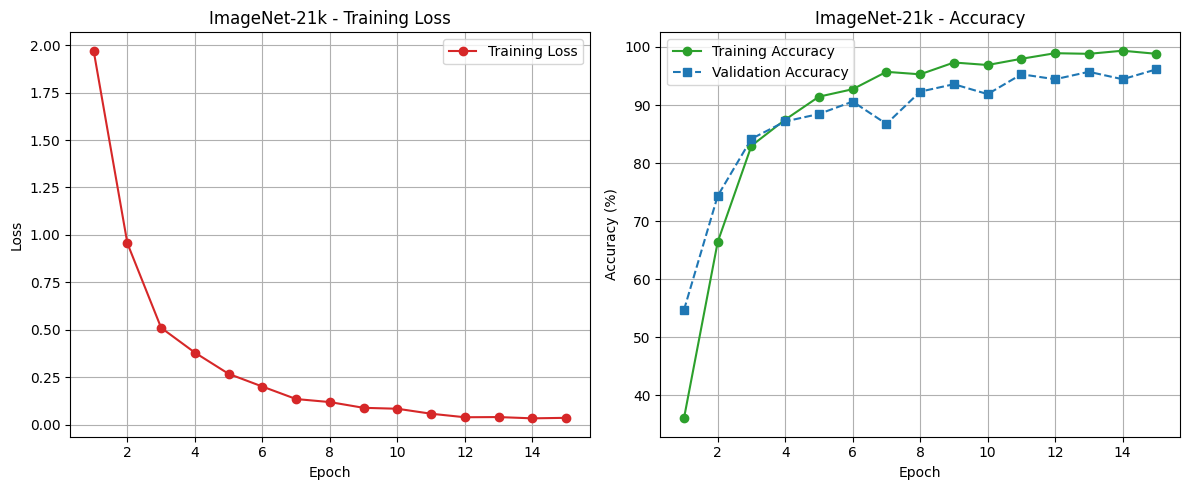


ImageNet-21k Results:
Test Accuracy: 85.56%
Test F1-Score: 0.8479
Test AUC-ROC: 0.9927

Training CLIP pretrained ViT
Number of classes: 12
Class names: ['Hip_DepuySynthes_Corail_Collar' 'Hip_DepuySynthes_Corail_NilCol'
 'Hip_JRIOrtho_FurlongEvolution_Collar'
 'Hip_JRIOrtho_FurlongEvolution_NilCol' 'Hip_SmithAndNephew_Anthology'
 'Hip_SmithAndNephew_Polarstem_NilCol' 'Hip_Stryker_AccoladeII'
 'Hip_Stryker_Exeter' 'Knee_Depuy_Synthes_Sigma'
 'Knee_SmithAndNephew_GenesisII' 'Knee_SmithAndNephew_Legion2'
 'Knee_ZimmerBiomet_Oxford']


pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Epoch 1/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=1.0181, Acc=50.48%]


Epoch [1/15]
Train Loss: 1.4684, Train Acc: 50.48%
Val Acc: 66.67%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=1.1414, Acc=82.46%]


...

Epoch [13/15]
Train Loss: 0.0022, Train Acc: 100.00%
Val Acc: 93.59%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=0.0020, Acc=100.00%]


Epoch [14/15]
Train Loss: 0.0021, Train Acc: 100.00%
Val Acc: 93.59%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=0.0024, Acc=100.00%]


Epoch [15/15]
Train Loss: 0.0021, Train Acc: 100.00%
Val Acc: 93.59%
--------------------------------------------------


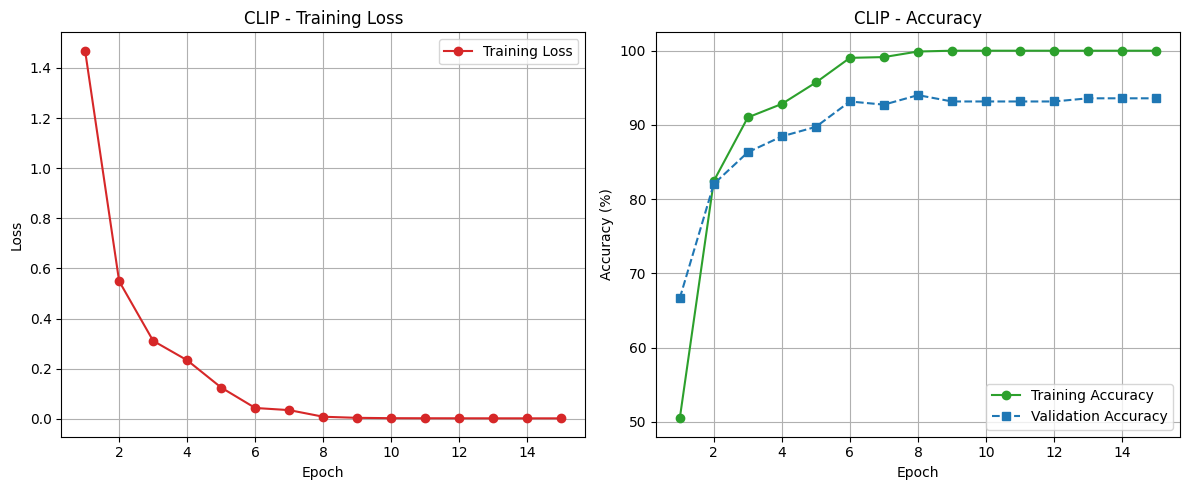


CLIP Results:
Test Accuracy: 87.22%
Test F1-Score: 0.8629
Test AUC-ROC: 0.9912

Training DINOv2 pretrained ViT
Number of classes: 12
Class names: ['Hip_DepuySynthes_Corail_Collar' 'Hip_DepuySynthes_Corail_NilCol'
 'Hip_JRIOrtho_FurlongEvolution_Collar'
 'Hip_JRIOrtho_FurlongEvolution_NilCol' 'Hip_SmithAndNephew_Anthology'
 'Hip_SmithAndNephew_Polarstem_NilCol' 'Hip_Stryker_AccoladeII'
 'Hip_Stryker_Exeter' 'Knee_Depuy_Synthes_Sigma'
 'Knee_SmithAndNephew_GenesisII' 'Knee_SmithAndNephew_Legion2'
 'Knee_ZimmerBiomet_Oxford']


model.safetensors:   0%|          | 0.00/343M [00:00<?, ?B/s]

Epoch 1/15: 100%|██████████| 30/30 [00:17<00:00,  1.68it/s, Loss=1.3661, Acc=42.03%]


Epoch [1/15]
Train Loss: 1.7173, Train Acc: 42.03%
Val Acc: 57.26%
--------------------------------------------------


Epoch 2/15: 100%|██████████| 30/30 [00:17<00:00,  1.69it/s, Loss=1.5388, Acc=72.62%]


...

Epoch [13/15]
Train Loss: 0.0249, Train Acc: 99.57%
Val Acc: 92.74%
--------------------------------------------------


Epoch 14/15: 100%|██████████| 30/30 [00:17<00:00,  1.69it/s, Loss=0.0012, Acc=99.79%] 


Epoch [14/15]
Train Loss: 0.0171, Train Acc: 99.79%
Val Acc: 91.88%
--------------------------------------------------


Epoch 15/15: 100%|██████████| 30/30 [00:17<00:00,  1.69it/s, Loss=0.0125, Acc=100.00%]


Epoch [15/15]
Train Loss: 0.0141, Train Acc: 100.00%
Val Acc: 91.88%
--------------------------------------------------


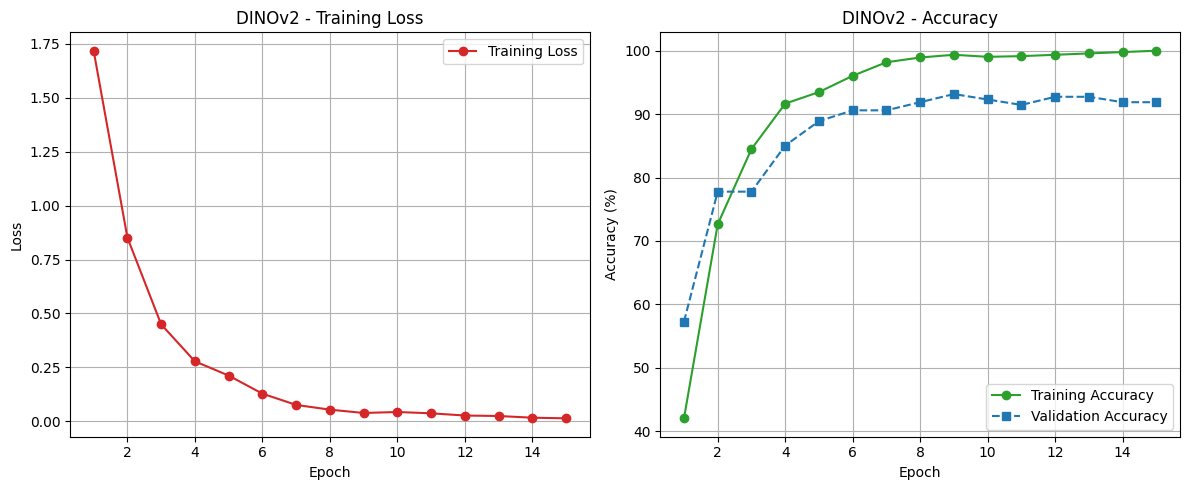


DINOv2 Results:
Test Accuracy: 82.78%
Test F1-Score: 0.8112
Test AUC-ROC: 0.9867

FINAL RESULTS COMPARISON
              Test Accuracy  Test F1-Score  Test AUC-ROC
ImageNet-21k        85.5556         0.8479        0.9927
CLIP                87.2222         0.8629        0.9912
DINOv2              82.7778         0.8112        0.9867


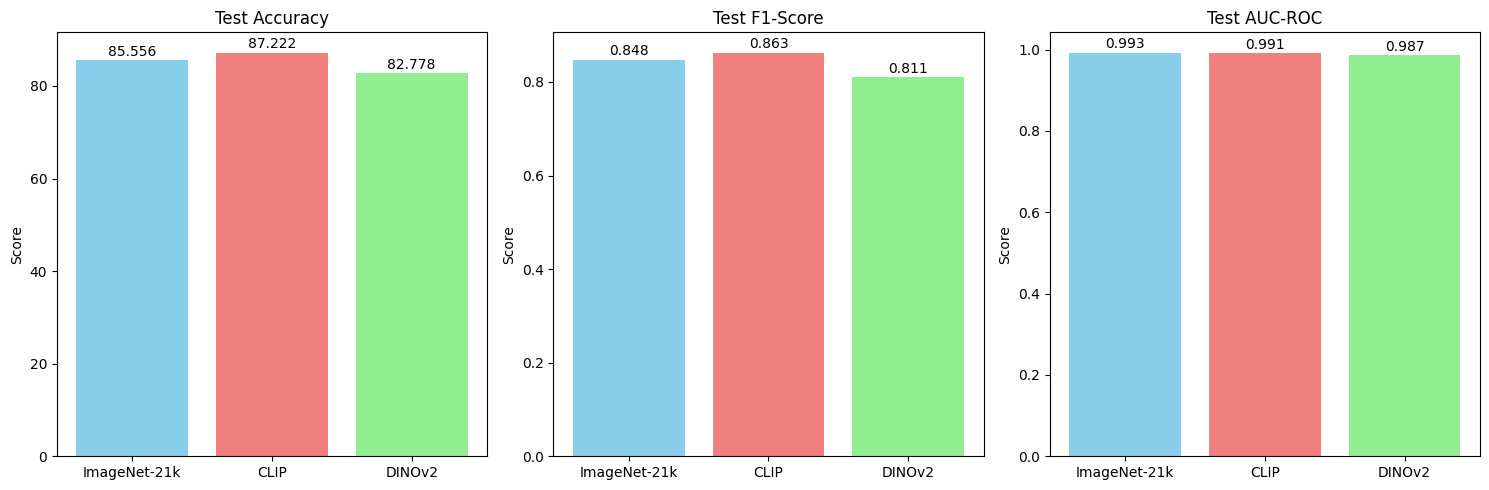

In [17]:
import gc
def main():
    """Main function to run the experiments"""
    
    # Set device
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using device: {device}")
    
    # Dataset paths
    train_csv_path = '/kaggle/input/orthonet-data/train.csv'
    test_csv_path = '/kaggle/input/orthonet-data/test.csv'
    images_root = '/kaggle/input/orthonet-data/orthonet data/orthonet data'  # Adjust if images are in a subfolder
    
    # Load and split data
    train_df, val_df, test_df = load_and_split_data(train_csv_path,test_csv_path)
    
    # Create transforms
    train_transform, val_transform = create_transforms()
    clip_processor = create_clip_processor()
    
    # Results storage
    results = {}
    
    # Model configurations
    pretrain_types = ['ImageNet-21k','CLIP','DINOv2']
    
    # Fit label encoder on training data
    label_encoder = LabelEncoder()
    label_encoder.fit(train_df['labels'])
    
    for pretrain_type in pretrain_types:
        print(f"\n{'='*60}")
        print(f"Training {pretrain_type} pretrained ViT")
        print(f"{'='*60}")
        
        # Create datasets
        if pretrain_type == 'CLIP':
            train_dataset = OrthonetDataset(train_df, images_root, processor=clip_processor)
            val_dataset = OrthonetDataset(val_df, images_root, processor=clip_processor)
            test_dataset = OrthonetDataset(test_df, images_root, processor=clip_processor)
        else:
            train_dataset = OrthonetDataset(train_df, images_root, transform=train_transform)
            val_dataset = OrthonetDataset(val_df, images_root, transform=val_transform)
            test_dataset = OrthonetDataset(test_df, images_root, transform=val_transform)
        
        # Create data loaders
        train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
        val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)
        test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
        
        # Get number of classes
        num_classes = train_dataset.num_classes
        print(f"Number of classes: {num_classes}")
        print(f"Class names: {label_encoder.classes_}")
        
        # Create model
        model = ViTWithCustomHead('vit_base_patch16_224', num_classes, pretrain_type)

        # Train model
        trained_model, train_losses, train_accuracies, val_accuracies = train_model(
            model, train_loader, val_loader, 
            num_epochs=15, lr=2e-5, device=device
        )

        # Plot training curves
        plot_training_curves(train_losses, train_accuracies, val_accuracies, pretrain_type)
        
        # Evaluate on test set
        test_acc, test_f1, test_auc = evaluate_model(trained_model, test_loader, device)
        
        # Store results
        results[pretrain_type] = {
            'Test Accuracy': test_acc,
            'Test F1-Score': test_f1,
            'Test AUC-ROC': test_auc
        }
        
        # Save model
        torch.save(trained_model.state_dict(), f'{pretrain_type.lower()}_vit_orthonet.pth')
        
        print(f"\n{pretrain_type} Results:")
        print(f"Test Accuracy: {test_acc:.2f}%")
        print(f"Test F1-Score: {test_f1:.4f}")
        print(f"Test AUC-ROC: {test_auc:.4f}")

        # Delete model/tensors
        del model
        gc.collect()
        
        # Clear PyTorch cache
        torch.cuda.empty_cache()
    
    # Create comparison table
    print(f"\n{'='*80}")
    print("FINAL RESULTS COMPARISON")
    print(f"{'='*80}")
    
    results_df = pd.DataFrame(results).T
    print(results_df.round(4))
    
    # Save results to CSV
    results_df.to_csv('vit_transfer_learning_results.csv')
    
    # Plot comparison
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    metrics = ['Test Accuracy', 'Test F1-Score', 'Test AUC-ROC']
    
    for i, metric in enumerate(metrics):
        values = [results[model][metric] for model in results.keys()]
        axes[i].bar(results.keys(), values, color=['skyblue', 'lightcoral', 'lightgreen'])
        axes[i].set_title(metric)
        axes[i].set_ylabel('Score')
        for j, v in enumerate(values):
            axes[i].text(j, v + 0.01 * max(values), f'{v:.3f}', ha='center')
    
    plt.tight_layout()
    plt.savefig('vit_comparison_results.png', dpi=300, bbox_inches='tight')
    plt.show()

if __name__ == "__main__":
    main()